In [2]:
# 24I-6034   Hamza Faheem     DS-B     DAV-LAB-02
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

df = sns.load_dataset('penguins')
df = df.dropna().reset_index(drop = True)
df.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female
4,Adelie,Torgersen,39.3,20.6,190.0,3650.0,Male


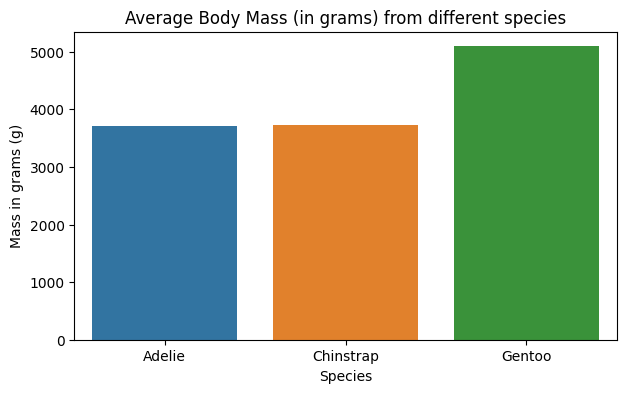

In [25]:
### TASK 1 ###
plt.figure(figsize = (7,4))
sns.barplot(data = df, x = 'species', y = 'body_mass_g', errorbar = None, hue = "species")
plt.title("Average Body Mass (in grams) from different species")
plt.xlabel("Species")
plt.ylabel("Mass in grams (g)")
plt.show()

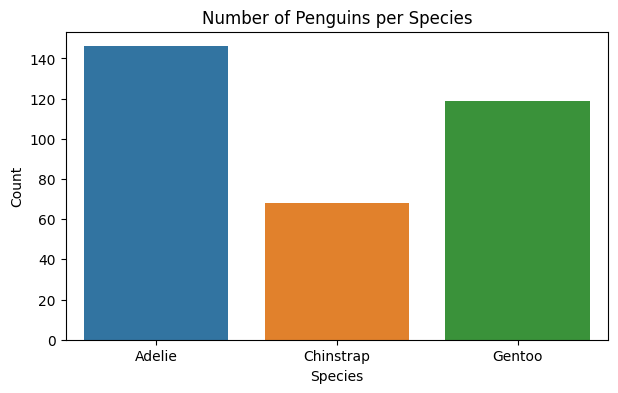

In [24]:
### TASK 2 ###
plt.figure(figsize = (7,4))
sns.countplot(data = df, x = 'species', hue = "species")
plt.title("Number of Penguins per Species")
plt.xlabel("Species")
plt.ylabel("Count")
plt.show()

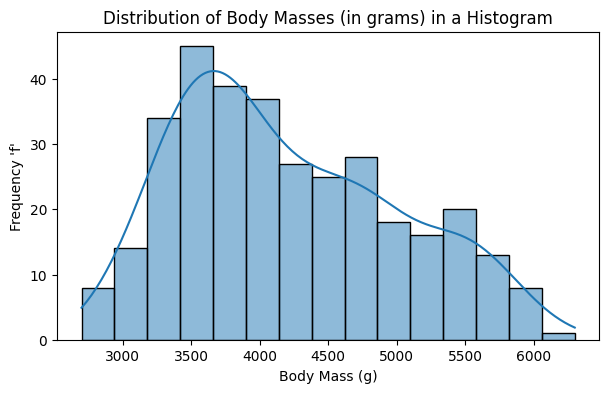

In [28]:
### TASK 3 ###
plt.figure(figsize = (7,4))
sns.histplot(data = df, x = "body_mass_g", bins = 15, kde = True)
plt.title("Distribution of Body Masses (in grams) in a Histogram")
plt.xlabel("Body Mass (g)")
plt.ylabel("Frequency 'f'")
plt.show()

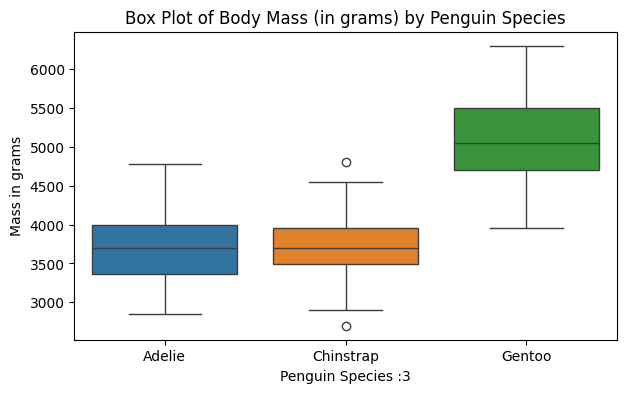

In [36]:
### TASK 4 ###
plt.figure(figsize = (7,4))
sns.boxplot(data = df, x = 'species', y = 'body_mass_g', hue = "species")
plt.title("Box Plot of Body Mass (in grams) by Penguin Species")
plt.xlabel("Penguin Species :3")
plt.ylabel("Mass in grams")
plt.show()

In [35]:
### TASK 5 ###
col = "body_mass_g"
Q1 = df[col].quantile(0.25)
Q3 = df[col].quantile(0.75)
IQR = Q3 - Q1
lowerB = Q1 - 1.5 * IQR
upperB = Q3 + 1.5 * IQR

outlierz = df[(df[col] < lowerB) | (df[col] > upperB)]
print(f"Number of outliers in Seaborn's Penguin Dataset : {len(outlierz)}")

Number of outliers in Seaborn's Penguin Dataset : 0


In [19]:
### TASK 6 ###
mean = df['body_mass_g'].mean()
std = df['body_mass_g'].std(ddof = 0)
df['z_score'] = (df["body_mass_g"] - mean) / std

outliers_of_zscore = df[np.abs(df['z_score']) > 3]
print(f"Number of Z-Score outliers = {len(outliers_of_zscore)}")

Number of Z-Score outliers = 0


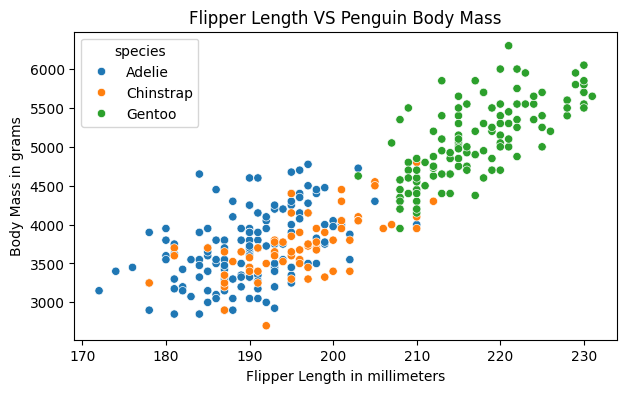

In [20]:
### TASK 7 ###
plt.figure(figsize = (7,4))
sns.scatterplot(data = df, x = "flipper_length_mm", y = "body_mass_g", hue = "species")
plt.title("Flipper Length VS Penguin Body Mass")
plt.xlabel("Flipper Length in millimeters")
plt.ylabel("Body Mass in grams")
plt.show()

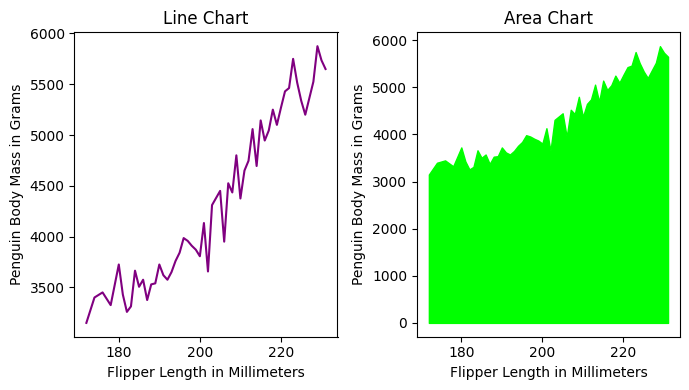

In [37]:
### TASK 8 ###
trend_df = df.groupby("flipper_length_mm")["body_mass_g"].mean().reset_index()
plt.figure(figsize = (7,4))

plt.subplot(1,2,1)
plt.plot(trend_df["flipper_length_mm"], trend_df["body_mass_g"], color = "purple")
plt.title("Line Chart")
plt.xlabel("Flipper Length in Millimeters")
plt.ylabel("Penguin Body Mass in Grams")

plt.subplot(1,2,2)
plt.fill_between(trend_df["flipper_length_mm"], trend_df["body_mass_g"], color = "lime")
plt.title("Area Chart")
plt.xlabel("Flipper Length in Millimeters")
plt.ylabel("Penguin Body Mass in Grams")
plt.tight_layout()
plt.show()

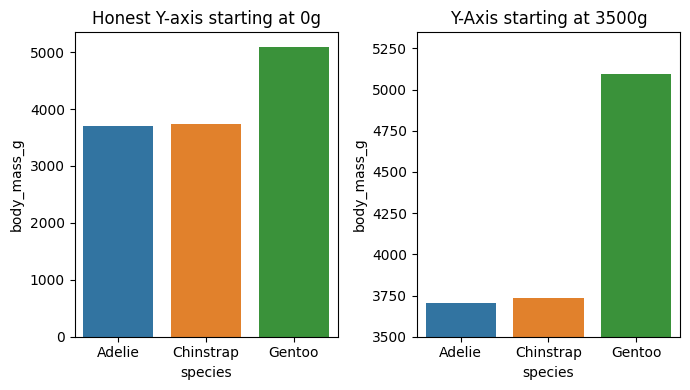

In [29]:
### TASK 9 ###
plt.figure(figsize = (7,4))
mean_mass = df.groupby('species')["body_mass_g"].mean().reset_index()

plt.subplot(1,2,1)
sns.barplot(data = mean_mass, x = 'species', y = 'body_mass_g', hue = 'species')
plt.title("Honest Y-axis starting at 0g")
plt.ylim(bottom = 0)

plt.subplot(1,2,2)
sns.barplot(data = mean_mass, x = 'species', y = 'body_mass_g', hue = 'species')
plt.title("Y-Axis starting at 3500g")
plt.ylim(bottom = 3500)

plt.tight_layout()
plt.show()

In [33]:
### EXPORTING penguins.csv ###
df.to_csv('24I6034_penguins.csv', index = False)